# Biomolecule toxicity: are Tox21-toxic compounds more lethal?

**Problem statement.** Take a chemical toxicity dataset from Kaggle or the UCI repository (Tox21 is a good one to start with). Find out how many compounds are toxic and how many are non-toxic. Then compare the average toxicity value (LD50 or whatever measure your dataset has) for the two groups. Is there a visible difference?

**Plan**
1. Get the data: Tox21 from Kaggle (with a direct-link fallback).
2. Count toxic and non-toxic compounds.
3. Tox21 has no LD50, so add rat oral LD50 values from a second public dataset and match the compounds by chemical structure.
4. Compare the average LD50 of the two groups, check whether the gap could be chance, and look at each assay.

Libraries: pandas, NumPy, Matplotlib (from class), plus `kagglehub` to download from Kaggle and `rdkit` to match chemical structures:
```
pip install pandas numpy matplotlib kagglehub rdkit
```

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

DATA = Path("../data/real")          # where the project keeps the real data
ASSAYS = ["NR-AR", "NR-AR-LBD", "NR-AhR", "NR-Aromatase", "NR-ER", "NR-ER-LBD", "NR-PPAR-gamma",
          "SR-ARE", "SR-ATAD5", "SR-HSE", "SR-MMP", "SR-p53"]
TOXIC, SAFE = "#d6336c", "#2566bd"   # colours for the two groups

## Step 1 · Get the data

Three ways to get Tox21 from Kaggle:

* **Website.** kaggle.com → search *Tox21* → open *epicskills/tox21-dataset* → **Download** → unzip the CSV.
* **Python with `kagglehub`** (below). Public datasets download without logging in. If Kaggle asks for a login: kaggle.com → Settings → API → **Generate New Token**, then run `kagglehub.login()` and paste it.
* **Command line.** `pip install kaggle`, `kaggle auth login`, then `kaggle datasets download -d epicskills/tox21-dataset --unzip`.

The cell below uses a saved copy if there is one, tries Kaggle next, and falls back to the MoleculeNet copy of the same data.

In [2]:
def load_tox21():
    local = DATA / "tox21.csv"
    if local.exists():
        print("Using the saved copy:", local)
        return pd.read_csv(local)
    try:
        import kagglehub
        folder = Path(kagglehub.dataset_download("epicskills/tox21-dataset"))
        for csv in folder.rglob("*.csv"):
            frame = pd.read_csv(csv)
            if set(ASSAYS) <= set(frame.columns):
                print("Downloaded from Kaggle:", csv)
                return frame
    except Exception as error:
        print("Kaggle download did not work:", error)
    url = "https://deepchemdata.s3-us-west-1.amazonaws.com/datasets/tox21.csv.gz"
    print("Downloading the MoleculeNet copy:", url)
    return pd.read_csv(url)

tox21 = load_tox21()
print(tox21.shape)
tox21.head()

Using the saved copy: ../data/real/tox21.csv
(7831, 14)


,NR-AR,NR-AR-LBD,NR-AhR,NR-Aromatase,NR-ER,NR-ER-LBD,NR-PPAR-gamma,SR-ARE,SR-ATAD5,SR-HSE,SR-MMP,SR-p53,mol_id,smiles
0,0.0,0.0,1.0,NaN,NaN,0.0,0.0,1.0,0.0,0.0,0.0,0.0,TOX3021,CCOc1ccc2nc(S(N)(=O)=O)sc2c1
1,0.0,0.0,0.0,0.0,0.0,0.0,0.0,NaN,0.0,NaN,0.0,0.0,TOX3020,CCN1C(=O)NC(c2ccccc2)C1=O
2,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.0,NaN,0.0,NaN,NaN,TOX3024,CC[C@]1(O)CC[C@H]2[C@@H]3CCC4=CCCC[C@@H]4[C@H]...
3,0.0,0.0,0.0,0.0,0.0,0.0,0.0,NaN,0.0,NaN,0.0,0.0,TOX3027,CCCN(CC)C(CC)C(=O)Nc1c(C)cccc1C
4,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,TOX20800,CC(O)(P(=O)(O)O)P(=O)(O)O


Each row is one compound, identified by `mol_id` and drawn as a `smiles` string. The 12 assay columns hold **1** (active: the compound caused the effect), **0** (inactive) or blank (not tested). *NR* assays look at nuclear receptors (hormone signalling); *SR* assays look at stress responses such as DNA damage, oxidative stress and mitochondrial damage.

## Step 2 · How many compounds are toxic?

Rule: **toxic** = active in at least one of the 12 assays; **non-toxic** = active in none of the assays it was tested in.

In [3]:
tox21["n_tested"] = tox21[ASSAYS].notna().sum(axis=1)
tox21["n_active"] = (tox21[ASSAYS] == 1).sum(axis=1)
tox21["toxic"] = (tox21["n_active"] > 0).astype(int)

counts = tox21["toxic"].value_counts().rename({1: "toxic", 0: "non-toxic"})
print(counts)
print(f"Toxic: {counts['toxic'] / len(tox21):.1%} of {len(tox21):,} compounds")
fully_tested = ((tox21["toxic"] == 0) & (tox21["n_tested"] == 12)).sum()
print(f"Non-toxic compounds tested in all 12 assays: {fully_tested:,}")

toxic
non-toxic    4959
toxic        2872
Name: count, dtype: int64
Toxic: 36.7% of 7,831 compounds
Non-toxic compounds tested in all 12 assays: 2,403


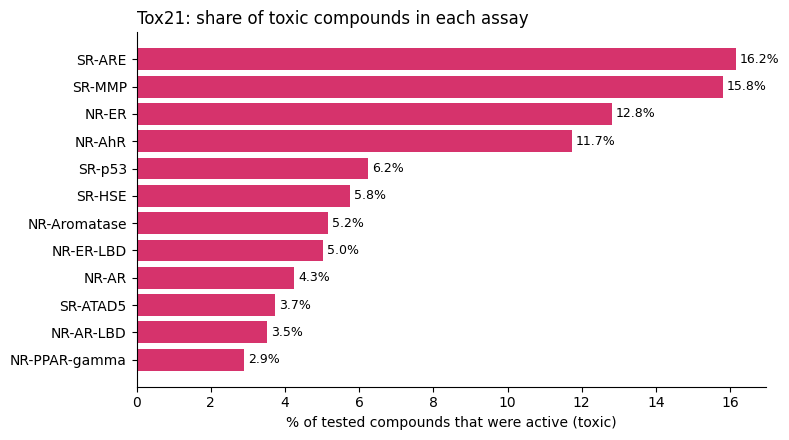

In [4]:
active_pct = ((tox21[ASSAYS] == 1).sum() / tox21[ASSAYS].notna().sum() * 100).sort_values()

fig, ax = plt.subplots(figsize=(8, 4.5))
bars = ax.barh(active_pct.index, active_pct.values, color=TOXIC)
ax.bar_label(bars, labels=[f"{v:.1f}%" for v in active_pct.values], padding=3, fontsize=9)
ax.set_xlabel("% of tested compounds that were active (toxic)")
ax.set_title("Tox21: share of toxic compounds in each assay", loc="left")
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()

## Step 3 · Add LD50 values

Tox21 only says yes or no, so it has no LD50. We take rat oral LD50 values from **LDToxDB** (13,329 compounds from NIH CATMoS, EPA TEST and NTP, published by the AI4PFAS project under the MIT licence). An alternative on Kaggle is *iapetus509/therapeutics-data-commons-acute-toxicity-ld50* (the TDC set, same units).

The values are stored as **−log(LD50 in mol/kg)**. A *higher* number means a *smaller* lethal dose, i.e. a *more toxic* compound.

In [5]:
ld50 = pd.read_csv("https://raw.githubusercontent.com/AI4PFAS/AI4PFAS/main/data/ldtoxdb-raw.csv")
print(ld50.shape)
ld50[["Chem_Name", "SMI", "NeglogLD50", "Source"]].head()

(13329, 6)


,Chem_Name,SMI,NeglogLD50,Source
0,Fenpirithrin,CC1(C)C(C=C(Cl)Cl)C1C(=O)OC(C#N)c1cccc(Oc2cccc...,2.957682,CATMOS
1,"4-Chloro-3,5-dimethylphenol",Cc1cc(O)cc(C)c1Cl,1.611626,CATMOS
2,Bisacodyl,CC(=O)Oc1ccc(C(c2ccc(OC(C)=O)cc2)c2ccccn2)cc1,1.924011,CATMOS
3,Dichlorprop,CC(Oc1ccc(Cl)cc1Cl)C(=O)O,2.532971,CATMOS
4,Methyl cinnamate,COC(=O)C=Cc1ccccc1,1.793378,CATMOS


The two tables write the same chemical in different ways (salts, charges, stereochemistry), so matching the SMILES text would miss most compounds. Instead we let RDKit reduce each structure to its main fragment and compute its **InChIKey**, a fixed-length fingerprint of the structure. The first 14 characters describe how the atoms are connected, so we match on those.

In [6]:
from rdkit import Chem, RDLogger
from rdkit.Chem import Descriptors
RDLogger.DisableLog("rdApp.*")

def structure_key(smiles):
    mol = Chem.MolFromSmiles(smiles) if isinstance(smiles, str) else None
    if mol is None:
        return None
    parent = max(Chem.GetMolFrags(mol, asMols=True), key=lambda m: m.GetNumHeavyAtoms())
    return Chem.MolToInchiKey(parent)[:14]

def molar_mass(smiles):
    mol = Chem.MolFromSmiles(smiles)
    return Descriptors.MolWt(mol) if mol else np.nan

tox21["key"] = tox21["smiles"].apply(structure_key)
ld50["key"] = ld50["SMI"].apply(structure_key)
# LD50 in mg/kg = 10^(-value) mol/kg x molar mass (g/mol) x 1000
ld50["log_mgkg"] = np.log10(10 ** (-ld50["NeglogLD50"]) * ld50["SMI"].apply(molar_mass) * 1000)

tox_by_key = tox21.dropna(subset=["key"]).groupby("key").agg(
    {"toxic": "max", **{a: "max" for a in ASSAYS}})
ld_by_key = ld50.dropna(subset=["key"]).groupby("key").agg(
    neglog_ld50=("NeglogLD50", "mean"), log_mgkg=("log_mgkg", "mean"), name=("Chem_Name", "first"))

data = tox_by_key.join(ld_by_key, how="inner")
data["ld50_mg_per_kg"] = 10 ** data["log_mgkg"]
print(f"{len(data):,} compounds have both a Tox21 result and an LD50")
data["toxic"].value_counts().rename({1: "toxic", 0: "non-toxic"})

3,831 compounds have both a Tox21 result and an LD50


toxic
non-toxic    2446
toxic        1385
Name: count, dtype: int64

## Step 4 · Compare the average LD50 of the two groups

In [7]:
summary = data.groupby("toxic").agg(
    compounds=("neglog_ld50", "size"),
    mean_neglog=("neglog_ld50", "mean"),
    median_neglog=("neglog_ld50", "median"),
    median_mg_per_kg=("ld50_mg_per_kg", "median"),
    mean_mg_per_kg=("ld50_mg_per_kg", "mean"),
).rename(index={1: "toxic in Tox21", 0: "non-toxic in Tox21"})
summary.round(2)

,compounds,mean_neglog,median_neglog,median_mg_per_kg,mean_mg_per_kg
toxic,,,,,
non-toxic in Tox21,2446,2.09,1.96,2254.0,3401.32
toxic in Tox21,1385,2.39,2.20,1609.0,2825.87


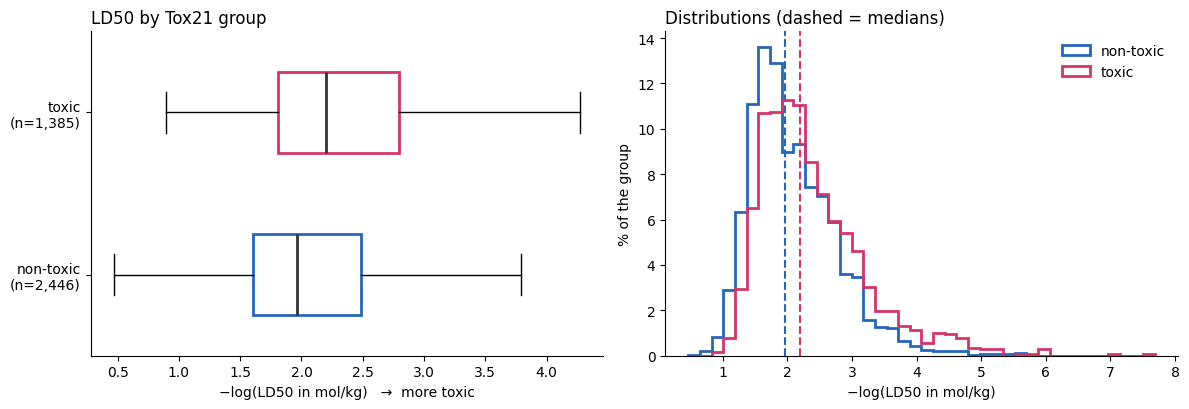

In [8]:
toxic = data.loc[data["toxic"] == 1, "neglog_ld50"].to_numpy()
safe = data.loc[data["toxic"] == 0, "neglog_ld50"].to_numpy()

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.2))
box = ax1.boxplot([safe, toxic], orientation="horizontal", widths=0.5, showfliers=False, patch_artist=True,
                  medianprops={"color": "#333333", "linewidth": 2})
for patch, color in zip(box["boxes"], [SAFE, TOXIC]):
    patch.set(facecolor="none", edgecolor=color, linewidth=2)
ax1.set_yticks([1, 2], [f"non-toxic\n(n={len(safe):,})", f"toxic\n(n={len(toxic):,})"])
ax1.set_xlabel("−log(LD50 in mol/kg)   →  more toxic")
ax1.set_title("LD50 by Tox21 group", loc="left")

bins = np.histogram_bin_edges(np.concatenate([toxic, safe]), bins=40)
for values, color, name in [(safe, SAFE, "non-toxic"), (toxic, TOXIC, "toxic")]:
    ax2.hist(values, bins=bins, weights=np.full(len(values), 100 / len(values)),
             histtype="step", linewidth=2, color=color, label=name)
    ax2.axvline(np.median(values), color=color, linestyle="--")
ax2.set_xlabel("−log(LD50 in mol/kg)")
ax2.set_ylabel("% of the group")
ax2.set_title("Distributions (dashed = medians)", loc="left")
ax2.legend(frameon=False)
for ax in (ax1, ax2):
    ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()

### Is the difference real, or chance?

A **permutation test** answers this with plain NumPy. If being toxic in Tox21 had nothing to do with LD50, the labels would be arbitrary. So we shuffle the labels 10,000 times and see how often chance alone produces a gap as large as the real one. **Cohen's d** measures how big the gap is compared with the spread (0.2 small, 0.5 medium, 0.8 large).

In [9]:
rng = np.random.default_rng(21)
observed = toxic.mean() - safe.mean()
pooled = np.concatenate([toxic, safe])
count = 0
for _ in range(10_000):
    rng.shuffle(pooled)
    if abs(pooled[:len(toxic)].mean() - pooled[len(toxic):].mean()) >= abs(observed):
        count += 1
p_value = (count + 1) / 10_001
cohens_d = observed / np.sqrt((toxic.var(ddof=1) + safe.var(ddof=1)) / 2)

print(f"Difference in mean −log(LD50): {observed:+.3f}")
print(f"That is {10 ** observed:.2f} times more toxic on average")
print(f"Permutation p-value: {p_value:.5f}  (shuffles as extreme as the real gap: {count})")
print(f"Cohen's d: {cohens_d:.2f}")

try:
    from scipy import stats            # optional cross-check with the usual tests
    print(stats.ttest_ind(toxic, safe, equal_var=False))
    print(stats.mannwhitneyu(toxic, safe))
except ImportError:
    pass

Difference in mean −log(LD50): +0.295
That is 1.97 times more toxic on average
Permutation p-value: 0.00010  (shuffles as extreme as the real gap: 0)
Cohen's d: 0.39


TtestResult(statistic=np.float64(11.209968173078067), pvalue=np.float64(1.7955436461752628e-28), df=np.float64(2431.243842470441))
MannwhitneyuResult(statistic=np.float64(2057471.5), pvalue=np.float64(2.068082175184826e-28))


### Which assays point to lethal compounds?

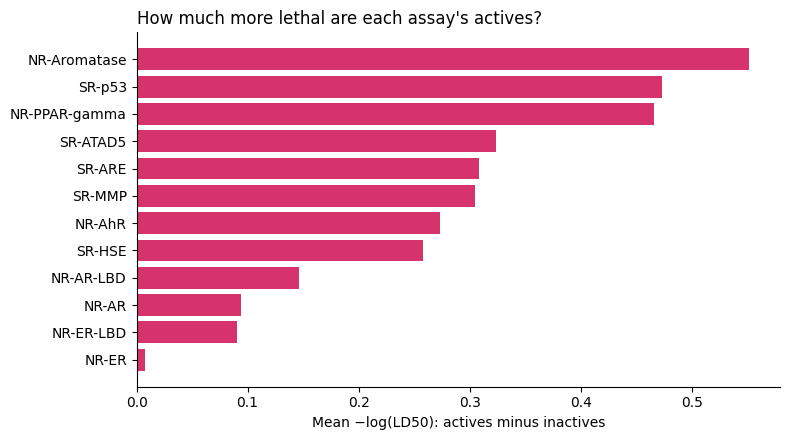

,assay,active,inactive,difference,times_more_toxic
0,NR-Aromatase,147,2881,0.552,3.57
1,SR-p53,186,3251,0.473,2.97
2,NR-PPAR-gamma,75,3231,0.466,2.93
3,SR-ATAD5,115,3466,0.324,2.11
4,SR-ARE,444,2607,0.308,2.03
5,SR-MMP,418,2560,0.305,2.02
6,NR-AhR,383,2975,0.273,1.88
7,SR-HSE,175,3151,0.258,1.81
8,NR-AR-LBD,86,3357,0.146,1.40
9,NR-AR,130,3507,0.094,1.24


In [10]:
rows = []
for assay in ASSAYS:
    active = data.loc[data[assay] == 1, "neglog_ld50"]
    inactive = data.loc[data[assay] == 0, "neglog_ld50"]
    diff = active.mean() - inactive.mean()
    rows.append({"assay": assay, "active": len(active), "inactive": len(inactive),
                 "difference": round(diff, 3), "times_more_toxic": round(10 ** diff, 2)})
per_assay = pd.DataFrame(rows).sort_values("difference", ascending=False, ignore_index=True)

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.barh(per_assay["assay"][::-1], per_assay["difference"][::-1], color=TOXIC)
ax.set_xlabel("Mean −log(LD50): actives minus inactives")
ax.set_title("How much more lethal are each assay's actives?", loc="left")
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()
per_assay

## Answer

* **How many are toxic?** Of 7,831 Tox21 compounds, **2,872 (36.7%) are toxic** (active in at least one assay) and **4,959 are non-toxic**. Only 2,403 of the non-toxic ones were tested in all 12 assays.
* **Is there a visible difference in LD50?** **Yes.** For the 3,831 compounds that also have an LD50, the toxic group's mean −log(LD50) is **2.39** against **2.09** for the non-toxic group. That is about **2 times more toxic** on average (median LD50 roughly 1,600 mg/kg against 2,250 mg/kg).
* **Is it real?** None of the 10,000 shuffles produced a gap that large (p ≈ 0.0001), so it is not chance. But Cohen's d is only about **0.4**: the two distributions overlap a lot, and many "non-toxic" compounds are still deadly.
* **Which assays matter?** Actives in the aromatase, p53 and PPAR-gamma assays are about 3 times more lethal; the estrogen and androgen receptor assays show almost no link to LD50.

**Why only a modest difference?** Tox21 measures specific effects on cells in a dish. LD50 measures death of a whole animal, which also depends on absorption, metabolism and how quickly the body clears the compound. The two agree on direction but are different measures of toxicity.

**Limitations.** Only half of Tox21 could be matched to an LD50; untested assays are treated as "not active"; LD50 values come from many labs and vary between studies.

**Sources.** Tox21 Data Challenge (NIH NCATS, EPA, FDA) via MoleculeNet/DeepChem and Kaggle. LDToxDB: Feinstein et al., *J. Chem. Inf. Model.* 2021 (AI4PFAS project), compiled from NIH CATMoS, EPA TEST and NTP.